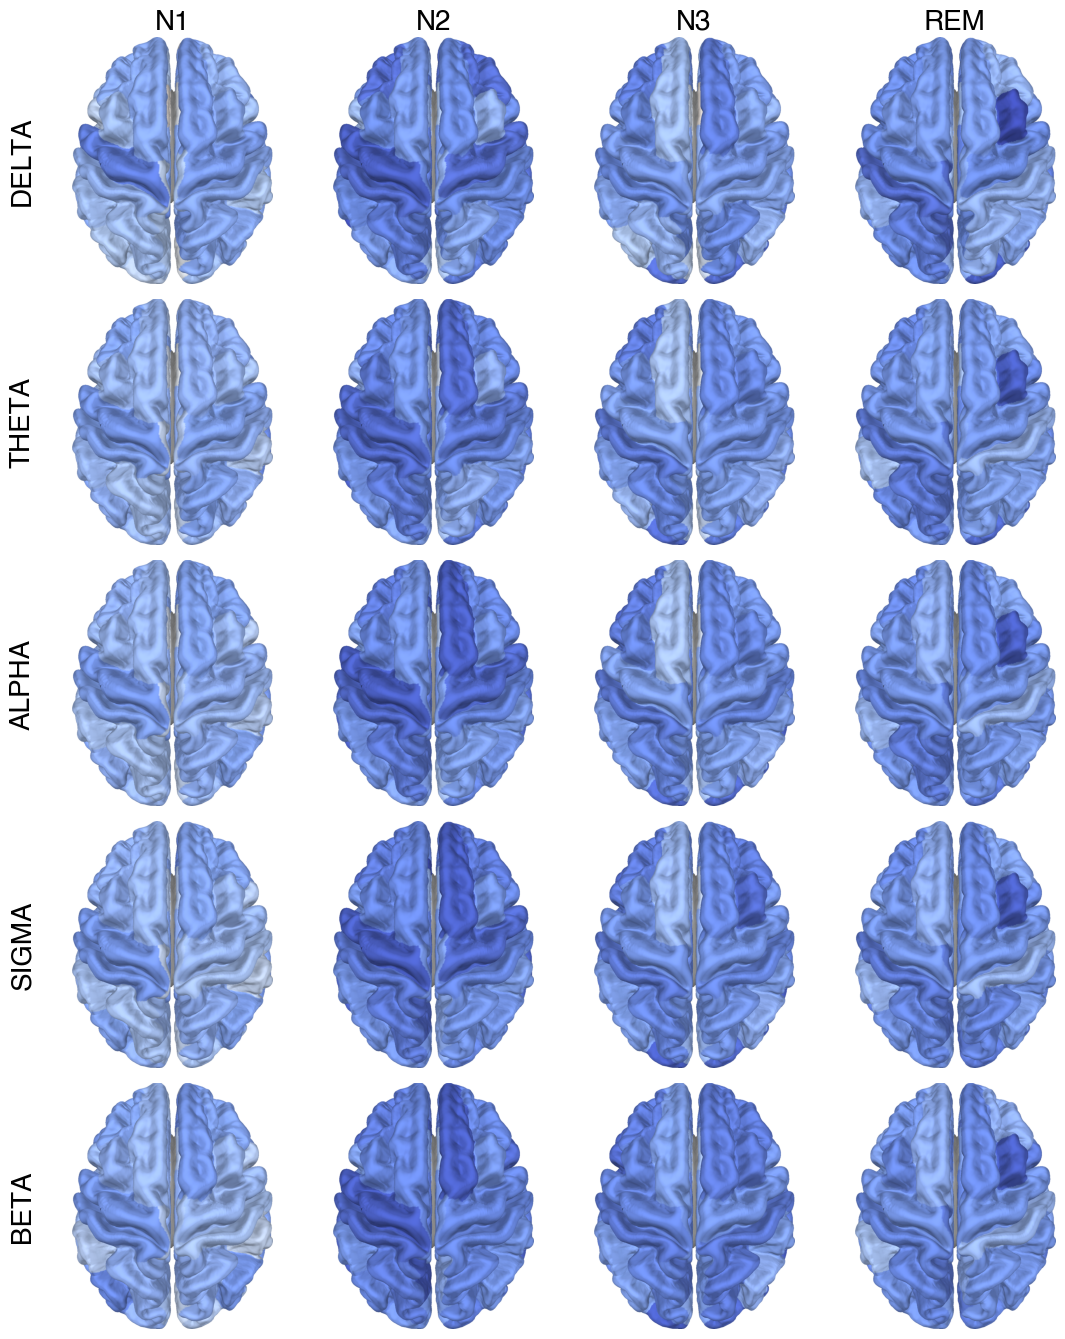

In [3]:
import matplotlib.pyplot as plt
from PIL import Image, ImageChops
from pathlib import Path
import matplotlib.font_manager as fm

# Define paths and labels
base_dir = Path("/Users/borjan/code/healthy-sleep-project/code/results/new_results_GC/figures/freq/mi")
frequencies = ['delta', 'theta', 'alpha', 'sigma', 'beta']
conditions = ['N1', 'N2', 'N3', 'REM']

# Set up the figure for a 5x4 grid (frequencies as rows, conditions as columns)
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(12, 15))

# Adjust the spacing between subplots to reduce whitespace
plt.subplots_adjust(wspace=-0.05, hspace=-0.05)

# Set the desired font properties for titles
title_font = {'fontsize': 20, 'fontweight': 'bold', 'fontname': 'Helvetica'}

def trim(im):
    bg = Image.new(im.mode, im.size, im.getpixel((0,0)))
    diff = ImageChops.difference(im, bg)
    bbox = diff.getbbox()
    if bbox:
        return im.crop(bbox)
    else:
        return im

# Loop over each frequency and condition to load the appropriate images
for i, freq in enumerate(frequencies):
    for j, condition in enumerate(conditions):
        # Construct file path
        if condition == "REM":
            file_name = f'mi_{freq}_R__brain_viz.png'
        else:
            file_name = f'mi_{freq}_{condition}_brain_viz.png'
        file_path = base_dir / file_name

        # Load and display the image if it exists
        if file_path.exists():
            img = Image.open(file_path)
            # Crop the image to remove whitespace
            img_cropped = trim(img)
            axes[i, j].imshow(img_cropped)
            axes[i, j].axis('off')  # Hide axes for a cleaner look
        else:
            print(f"Warning: {file_path} not found.")
            axes[i, j].axis('off')

        # Add column titles (for each sleep stage) at the top of each column
        if i == 0:
            axes[i, j].set_title(condition, **title_font)

# Adjust layout to ensure everything fits well
plt.tight_layout(rect=[0.08, 0.05, 1, 0.95])  # Leave space for row labels

# Add row labels (for each frequency)
row_labels = [freq.upper() for freq in frequencies]
row_font = {'fontsize': 20, 'fontweight': 'bold', 'fontname': 'Helvetica'}

for i, label in enumerate(row_labels):
    # Get the position of the first subplot in each row
    pos = axes[i, 0].get_position()
    # Calculate the center y-position of the subplot
    y_pos = pos.y0 + pos.height / 2
    # Adjust x-position to align labels closer to the subplots
    x_pos = pos.x0 - 0.03  # Adjust this value as needed
    fig.text(x_pos, y_pos, label, va='center', ha='right', rotation=90, **row_font)

# Define output paths
output_path_png = base_dir / "MI_composite_brain_visualization_adjusted.png"
output_path_pdf = base_dir / "MI_composite_brain_visualization_adjusted.pdf"
output_path_eps = base_dir / "MI_composite_brain_visualization_adjusted.eps"

# Save the figure in PNG, PDF, and EPS formats
fig.savefig(output_path_png, dpi=300, bbox_inches='tight')
fig.savefig(output_path_pdf, format='pdf', bbox_inches='tight')
fig.savefig(output_path_eps, format='eps', bbox_inches='tight')

plt.show()
